# Part A: Problem Understanding

**Q1. What is churn?**
Churn means a customer cancels their ConnectTel subscription. One row is one customer, for example a customer with tenure 2 months, a Month-to-month contract and MonthlyCharges 53.85 who left. The inputs are the customer's profile, account/billing and service columns. The target is Churn (No = 0, Yes = 1). Because the target has two categories, the core task is classification, not regression.

**Q2. False negative vs false positive**
A false negative means the model says a customer will stay but the customer leaves, so the retention team never contacts them and the revenue is lost. A false positive means the model flags a customer who would have stayed, so the team wastes effort or a discount on them. A false negative usually costs more, but this depends on the cost of a retention offer. To decide, I would need the average revenue per customer, the cost of a retention call or discount, and how often offers actually succeed.

**Q3. Hypotheses to test (not facts)**
1. Customers on Month-to-month contracts churn more than customers on One-year or Two-year contracts.
2. Customers with short tenure churn more than long-tenure customers.
3. Customers without TechSupport or OnlineSecurity churn more than those with these services.

**Q4. Why customerID and Churn are not inputs**
customerID is only a unique label with no real meaning; a tree could memorise it and overfit without learning anything that generalises. Churn is the answer itself. Using it as an input is target leakage: the model would look perfect but be useless, because for a real customer we do not know the outcome in advance.

**Q5. What the data can and cannot establish**
The data shows associations between customer attributes and churn at one point in time. It cannot prove that a discount will prevent churn, because association is not causation. It also cannot support prospective forecasting, because we do not know when each feature was recorded or whether there is a future outcome window. This is an educational task on one (fictional) company's data, not a production-ready forecasting system.

# Part B: Manual Split Calculations

| Customer | Contract | Tenure (months) | Churn |
|---|---|---|---|
| A | Monthly | 2 | Yes |
| B | Monthly | 4 | Yes |
| C | Monthly | 8 | No |
| D | Monthly | 12 | Yes |
| E | Annual | 3 | No |
| F | Annual | 9 | No |
| G | Annual | 18 | No |
| H | Annual | 24 | Yes |

In [2]:
import numpy as np

labels = ["Yes", "Yes", "No", "Yes", "No", "No", "No", "Yes"]

def gini(lbls):
    n = len(lbls)
    if n == 0:
        return 0
    p_yes = lbls.count("Yes") / n
    p_no = lbls.count("No") / n
    return 1 - (p_yes ** 2 + p_no ** 2)

def entropy(lbls):
    n = len(lbls)
    if n == 0:
        return 0
    total = 0
    for cls in ["Yes", "No"]:
        p = lbls.count(cls) / n
        if p > 0:
            total -= p * np.log2(p)
    return total

print("Root Gini:", round(gini(labels), 4))
print("Root Entropy:", round(entropy(labels), 4))

Root Gini: 0.5
Root Entropy: 1.0


In [3]:
customers = {
    "A": ("Monthly", 2, "Yes"),
    "B": ("Monthly", 4, "Yes"),
    "C": ("Monthly", 8, "No"),
    "D": ("Monthly", 12, "Yes"),
    "E": ("Annual", 3, "No"),
    "F": ("Annual", 9, "No"),
    "G": ("Annual", 18, "No"),
    "H": ("Annual", 24, "Yes"),
}

def evaluate_split(name, left_ids, right_ids):
    left = [customers[c][2] for c in left_ids]
    right = [customers[c][2] for c in right_ids]
    n = len(left) + len(right)

    w_gini = (len(left)/n) * gini(left) + (len(right)/n) * gini(right)
    w_ent = (len(left)/n) * entropy(left) + (len(right)/n) * entropy(right)

    print(name)
    print("  Left labels :", left, "| Gini:", round(gini(left), 4), "| Entropy:", round(entropy(left), 4))
    print("  Right labels:", right, "| Gini:", round(gini(right), 4), "| Entropy:", round(entropy(right), 4))
    print("  Weighted Gini   :", round(w_gini, 4), "| Reduction:", round(gini(labels) - w_gini, 4))
    print("  Weighted Entropy:", round(w_ent, 4), "| Reduction:", round(entropy(labels) - w_ent, 4))
    print()

monthly = [c for c, v in customers.items() if v[0] == "Monthly"]
annual = [c for c, v in customers.items() if v[0] == "Annual"]
evaluate_split("Split 1: Contract = Monthly vs Annual", monthly, annual)

short = [c for c, v in customers.items() if v[1] <= 6]
long_ = [c for c, v in customers.items() if v[1] > 6]
evaluate_split("Split 2: Tenure <= 6 vs > 6", short, long_)

Split 1: Contract = Monthly vs Annual
  Left labels : ['Yes', 'Yes', 'No', 'Yes'] | Gini: 0.375 | Entropy: 0.8113
  Right labels: ['No', 'No', 'No', 'Yes'] | Gini: 0.375 | Entropy: 0.8113
  Weighted Gini   : 0.375 | Reduction: 0.125
  Weighted Entropy: 0.8113 | Reduction: 0.1887

Split 2: Tenure <= 6 vs > 6
  Left labels : ['Yes', 'Yes', 'No'] | Gini: 0.4444 | Entropy: 0.9183
  Right labels: ['No', 'Yes', 'No', 'No', 'Yes'] | Gini: 0.48 | Entropy: 0.971
  Weighted Gini   : 0.4667 | Reduction: 0.0333
  Weighted Entropy: 0.9512 | Reduction: 0.0488



## Split comparison

| Split | Weighted Gini | Gini reduction | Weighted Entropy | Entropy reduction |
|---|---|---|---|---|
| Contract (Monthly vs Annual) | 0.375 | 0.125 | 0.8113 | 0.1887 |
| Tenure <= 6 vs > 6 | 0.4667 | 0.0333 | 0.9512 | 0.0488 |

Root impurity: Gini = 0.5, Entropy = 1.0.

**Decision:** Contract is the better root split under both criteria because it gives the larger impurity reduction. It separates the customers into a mostly-churn group (Monthly: 3 of 4 churn) and a mostly-stay group (Annual: 3 of 4 stay).

In [4]:
annual_ids = ["E", "F", "G", "H"]
left_ids = [c for c in annual_ids if customers[c][1] <= 18]
right_ids = [c for c in annual_ids if customers[c][1] > 18]

left = [customers[c][2] for c in left_ids]
right = [customers[c][2] for c in right_ids]
parent = [customers[c][2] for c in annual_ids]

n = len(parent)
weighted = (len(left)/n) * gini(left) + (len(right)/n) * gini(right)

print("Annual parent Gini:", round(gini(parent), 4))
print("Left (Tenure <= 18):", left_ids, left, "Gini:", gini(left))
print("Right (Tenure > 18):", right_ids, right, "Gini:", gini(right))
print("Weighted Gini:", round(weighted, 4))
print("Reduction:", round(gini(parent) - weighted, 4))

Annual parent Gini: 0.375
Left (Tenure <= 18): ['E', 'F', 'G'] ['No', 'No', 'No'] Gini: 0.0
Right (Tenure > 18): ['H'] ['Yes'] Gini: 0.0
Weighted Gini: 0.0
Reduction: 0.375


## Tree and terms

    Contract = Monthly ?              <- root node (a question about an input)
     |-- Yes (Monthly) -> LEAF: predict Churn = Yes, P(Yes) = 3/4 = 0.75
     |-- No (Annual)   -> Tenure <= 18 ?   <- internal (decision) node
                           |-- Yes -> LEAF (E, F, G): predict No,  P(Yes) = 0/3 = 0.00
                           |-- No  -> LEAF (H):       predict Yes, P(Yes) = 1/1 = 1.00

- **Root node:** the first question, at the top (Contract).
- **Decision/internal node:** a question that is not the first (Tenure <= 18).
- **Branch:** the Yes/No answer line from a question to the next node.
- **Leaf:** a final box with no further question; it gives the prediction.
- A split is a question about an input because the tree can only ask about the input columns (Contract, Tenure) and routes each customer by the answer.

## Leaf probabilities and ties
A leaf predicts the majority class, and its probability is the class proportion in that leaf (for example Monthly: 3 Yes out of 4 = 0.75). If a leaf is tied (for example 1 Yes and 1 No), I would not pick randomly: in scikit-learn the tie goes to the first class in sorted order (No). For churn I would rather flag the customer as Yes, because a false negative usually costs more, and I would say so in the report.

## Why greedy is not guaranteed best
The tree picks the best split at each step using only that step's impurity reduction. It never looks ahead, so a split that looks slightly worse now could lead to a better tree later. The result is a good tree, not guaranteed the globally best one. A numerical tree also does not pick a "sensible" threshold such as 6 months: it tests candidate thresholds between the sorted values and chooses the one with the best impurity reduction.

# Part C: Data Audit and Leakage-Free Setup

In [8]:
import pandas as pd
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Shape:", df.shape)
print("\nDtypes:")
print(df.dtypes)

print("\nMissing values (NaN):", df.isnull().sum().sum())

blank_counts = df.astype(str).apply(lambda s: (s.str.strip() == "").sum())
print("\nBlank strings per column (only columns with blanks):")
print(blank_counts[blank_counts > 0])

print("\nDuplicate rows:", df.duplicated().sum())
print("Repeated customerIDs:", df["customerID"].duplicated().sum())

print("\nChurn counts:")
print(df["Churn"].value_counts())
print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Shape: (7043, 21)

Dtypes:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values (NaN): 0

Blank strings per column (only columns with blanks):
TotalCharges    11
dtype: int64

Duplicate rows: 0
Repeated customerIDs: 0

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [9]:
import pandas as pd

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

tc_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
invalid_rows = df[tc_numeric.isnull()]

print("Invalid TotalCharges entries:", len(invalid_rows))
print("Unique raw values:", invalid_rows["TotalCharges"].unique())
invalid_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Invalid TotalCharges entries: 11
Unique raw values: <StringArray>
[' ']
Length: 1, dtype: str


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


,Check,Result
0,Rows,7043
1,Columns,21
2,NaN cells,0
3,Blank TotalCharges,11
4,Duplicate rows,0
5,Repeated customerIDs,0


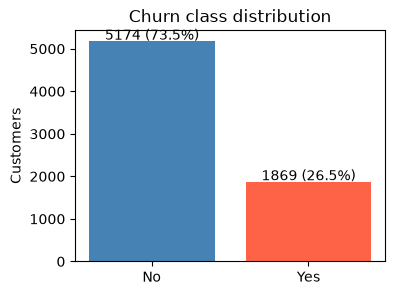

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

quality = pd.DataFrame({
    "Check": ["Rows", "Columns", "NaN cells", "Blank TotalCharges",
              "Duplicate rows", "Repeated customerIDs"],
    "Result": [df.shape[0], df.shape[1], int(df.isnull().sum().sum()),
               int((df["TotalCharges"].astype(str).str.strip() == "").sum()),
               int(df.duplicated().sum()), int(df["customerID"].duplicated().sum())]
})
display(quality)

counts = df["Churn"].value_counts()
plt.figure(figsize=(4, 3))
plt.bar(counts.index, counts.values, color=["steelblue", "tomato"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 40, f"{v} ({v / len(df) * 100:.1f}%)", ha="center")
plt.title("Churn class distribution")
plt.ylabel("Customers")
plt.show()

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

# Deterministic fixes only (no learning from data)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})  # category, not a number

ids = df["customerID"]
y = (df["Churn"] == "Yes").astype(int)          # Yes = 1 (positive class)
X = df.drop(columns=["customerID", "Churn"])

# 80% development / 20% sealed test
X_dev, X_test, y_dev, y_test, ids_dev, ids_test = train_test_split(
    X, y, ids, test_size=0.20, stratify=y, random_state=SEED)

# development -> 75% train / 25% validation (about 60/20/20 overall)
X_train, X_val, y_train, y_val, ids_train, ids_val = train_test_split(
    X_dev, y_dev, ids_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

for name, part in [("Train", y_train), ("Validation", y_val), ("Test (sealed)", y_test)]:
    print(f"{name:14s} rows={len(part):5d}  churn rate={part.mean():.4f}")

Train          rows= 4225  churn rate=0.2653
Validation     rows= 1409  churn rate=0.2654
Test (sealed)  rows= 1409  churn rate=0.2654


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
])

print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)
preprocessor

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [13]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score)

dummy = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent")),
])
dummy.fit(X_train, y_train)

pred = dummy.predict(X_val)
proba = dummy.predict_proba(X_val)[:, 1]

baseline = {
    "Accuracy": accuracy_score(y_val, pred),
    "Churn precision": precision_score(y_val, pred, zero_division=0),
    "Churn recall": recall_score(y_val, pred),
    "Churn F1": f1_score(y_val, pred),
    "Average precision": average_precision_score(y_val, proba),
}
pd.DataFrame(baseline, index=["Dummy (most_frequent)"]).round(4)

,Accuracy,Churn precision,Churn recall,Churn F1,Average precision
Dummy (most_frequent),0.7346,0.0,0.0,0.0,0.2654


## Part C notes

**Invalid TotalCharges:** the 11 blank values all belong to customers with tenure 0 (new customers with no first bill yet). They are converted to missing and imputed with the training median inside the pipeline, not deleted.

**Duplicates / repeated IDs:** none found, so a normal stratified split is valid and no grouped split is needed.

**Split:** 60% train, 20% validation, 20% sealed test, stratified, random_state=42. The test set is not used for any choice.

**Why no leakage:** imputation and encoding live inside the Pipeline and are fitted only on training rows (and only on training folds during cross-validation).

**Why trees do not need standardisation:** a split asks "is feature <= threshold?", which depends only on the order of values, not their scale. Arbitrary numeric category codes (for example Month-to-month = 0, One year = 1, Two year = 2) would invent an order and a distance that do not exist, so I use one-hot encoding.

**Why accuracy misleads:** the dummy model predicts "No" for everyone and still gets about 73% accuracy, but it finds zero churners (recall 0). Churn precision, recall, F1 and average precision show what accuracy hides.

# Part D: Build, Explain and Prune a Decision Tree